In [1]:
from pathlib import Path
import xarray as xr
import numpy as np
import tempfile
import subprocess
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.spatial import cKDTree
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
import ipywidgets as widgets
from IPython.display import display, clear_output
import re


In [2]:
ds = xr.open_dataset("incr-co2-sstdelta-remap.grib", engine="cfgrib")

print(ds)
print(ds.data_vars)

<xarray.Dataset> Size: 33MB
Dimensions:    (values: 1661440)
Coordinates:
    latitude   (values) float64 13MB ...
    longitude  (values) float64 13MB ...
    step       timedelta64[ns] 8B ...
    surface    float64 8B ...
Dimensions without coordinates: values
Data variables:
    unknown    (values) float32 7MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             0
    GRIB_centreDescription:  Absent
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             Absent
    history:                 2026-07-30T02:25 GRIB to CDM+CF via cfgrib-0.9.1...
Data variables:
    unknown  (values) float32 7MB ...


First few cells are for checking if the remapping I am doing is correct

In [3]:
def remap_grib_and_apply_to_sst(
    grib_path,
    init_nc_path,
    out_nc_path,
    target_var="sea_surface_temperature",
    cdo_bin="cdo",
):
    """
    Regularise a reduced-Gaussian GRIB with CDO, remap it to the target
    NetCDF lon/lat grid, verify the remap worked, and apply the delta to SST.

    Parameters
    ----------
    grib_path : str or Path
        Input GRIB file (e.g. pi-co2-sstdelta-remap.grib)
    init_nc_path : str or Path
        Target initialisation NetCDF (e.g. init_2021-06-25T12_10d.nc)
    out_nc_path : str or Path
        Output NetCDF to write
    target_var : str
        Variable in the NetCDF to add the delta to
    cdo_bin : str
        CDO executable name/path

    Returns
    -------
    out_ds : xarray.Dataset
        Dataset after delta application
    remap_ds : xarray.Dataset
        The remapped delta dataset opened from CDO output
    """
    grib_path = Path(grib_path)
    init_nc_path = Path(init_nc_path)
    out_nc_path = Path(out_nc_path)

    # Load target dataset
    init_ds = xr.open_dataset(init_nc_path)
    if target_var not in init_ds:
        raise KeyError(f"{target_var!r} not found in {init_nc_path}")

    if "lat" not in init_ds.coords or "lon" not in init_ds.coords:
        raise ValueError("Target NetCDF must have 'lat' and 'lon' coordinates")

    lat = init_ds["lat"].values
    lon = init_ds["lon"].values

    # Build a CDO grid description file for the target grid
    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        gridfile = tmpdir / "target_grid.txt"
        regular_grib = tmpdir / "regularised.grib"
        remap_nc = tmpdir / "remapped.nc"

        with gridfile.open("w") as f:
            f.write("gridtype = lonlat\n")
            f.write(f"xsize    = {len(lon)}\n")
            f.write(f"ysize    = {len(lat)}\n")
            f.write(f"xfirst   = {float(lon[0])}\n")
            f.write(f"xinc     = {float(lon[1] - lon[0])}\n")
            f.write(f"yfirst   = {float(lat[0])}\n")
            f.write(f"yinc     = {float(lat[1] - lat[0])}\n")

        # 1) Regularise reduced Gaussian grid
        cmd1 = [cdo_bin, "setgridtype,regular", str(grib_path), str(regular_grib)]
        subprocess.run(cmd1, check=True)

        # 2) Remap onto target lon/lat grid
        cmd2 = [cdo_bin, "-f", "nc", f"remapbil,{gridfile}", str(regular_grib), str(remap_nc)]
        subprocess.run(cmd2, check=True)

        # Re-open remapped output
        remap_ds = xr.open_dataset(remap_nc, use_cftime=True)

        if len(remap_ds.data_vars) == 0:
            raise RuntimeError("Remapped file contains no data variables")

        delta_name = list(remap_ds.data_vars)[0]
        delta = remap_ds[delta_name]

        # CDO often leaves a dummy time axis of length 1
        if "time" in delta.dims and delta.sizes["time"] == 1:
            delta = delta.isel(time=0)

        # Make sure the result is a 2D lat/lon field
        if set(delta.dims) != {"lat", "lon"}:
            raise RuntimeError(
                f"Remapped field has unexpected dims {delta.dims}; expected ('lat', 'lon')"
            )

        # Verify grid match
        if delta.shape != (len(lat), len(lon)):
            raise RuntimeError(
                f"Remapped shape {delta.shape} does not match target grid {(len(lat), len(lon))}"
            )

        if not np.allclose(delta["lat"].values, lat):
            raise RuntimeError("Latitude coordinates do not match the target grid")

        if not np.allclose(delta["lon"].values, lon):
            raise RuntimeError("Longitude coordinates do not match the target grid")

        # Apply delta to the target variable. xarray will broadcast lat/lon
        # across batch/time automatically.
        delta_da = xr.DataArray(
            delta.values,
            coords={"lat": init_ds["lat"], "lon": init_ds["lon"]},
            dims=("lat", "lon"),
            name=f"{target_var}_delta",
        )

        out_ds = init_ds.copy()
        out_ds[target_var] = init_ds[target_var] + delta_da

        out_ds.to_netcdf(out_nc_path)

    return out_ds, remap_ds

In [4]:
def test_remap_grib_and_apply_to_sst(
    grib_path,
    init_nc_path,
    target_var="sea_surface_temperature",
    cdo_bin="cdo",
):
    """
    Dry-run test:
    - writes to a temporary output file
    - verifies remap grid
    - verifies SST changed
    - prints a small summary
    """
    grib_path = Path(grib_path)
    init_nc_path = Path(init_nc_path)

    with tempfile.TemporaryDirectory() as tmpdir:
        tmpdir = Path(tmpdir)
        test_out = tmpdir / "test_output.nc"

        out_ds, remap_ds = remap_grib_and_apply_to_sst(
            grib_path=grib_path,
            init_nc_path=init_nc_path,
            out_nc_path=test_out,
            target_var=target_var,
            cdo_bin=cdo_bin,
        )

        init_ds = xr.open_dataset(init_nc_path, use_cftime=True)

        delta_name = list(remap_ds.data_vars)[0]
        delta = remap_ds[delta_name]
        if "time" in delta.dims and delta.sizes["time"] == 1:
            delta = delta.isel(time=0)

        assert delta.dims == ("lat", "lon"), f"Unexpected delta dims: {delta.dims}"
        assert delta.shape == (init_ds.sizes["lat"], init_ds.sizes["lon"]), "Grid shape mismatch"
        assert np.allclose(delta["lat"].values, init_ds["lat"].values), "Latitude mismatch"
        assert np.allclose(delta["lon"].values, init_ds["lon"].values), "Longitude mismatch"

        before = init_ds[target_var].values
        after = out_ds[target_var].values
        diff = after - before

        assert np.nanmax(np.abs(diff)) > 0, "No change applied to target variable"
        assert test_out.exists(), "Temporary output file was not written"

        print("Test passed.")
        print("Remapped variable:", delta_name)
        print("Delta min/max:", float(np.nanmin(delta.values)), float(np.nanmax(delta.values)))
        print("Applied diff min/max:", float(np.nanmin(diff)), float(np.nanmax(diff)))

In [5]:
test_remap_grib_and_apply_to_sst(
    grib_path="pi-co2-sstdelta-remap.grib",
    init_nc_path="init_files/init_2021-06-25T12_10d.nc",
    target_var="sea_surface_temperature",
)

/tmp/user/28413/ipykernel_3558741/3350190960.py:37: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  init_ds = xr.open_dataset(init_nc_path)


cdo    remapbil: Bilinear weights from gaussian (2576x1280) to lonlat (360x181) grid


/tmp/user/28413/ipykernel_3558741/3350190960.py:72: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  remap_ds = xr.open_dataset(remap_nc, use_cftime=True)


Test passed.
Remapped variable: code1
Delta min/max: -5.449851989746094 1.3921808004379272
Applied diff min/max: -5.449859619140625 1.392181396484375


/tmp/user/28413/ipykernel_3558741/2055833970.py:29: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  init_ds = xr.open_dataset(init_nc_path, use_cftime=True)
/tmp/user/28413/ipykernel_3558741/2055833970.py:29: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_t

In [6]:
#Code to 
out_ds, remap_ds = remap_grib_and_apply_to_sst(
    grib_path="incr-co2-sstdelta-remap.grib",
    init_nc_path="init_files/init_2021-06-25T12_10d.nc",
    out_nc_path="incr_co2_withsstdelta_init_2021-06-25T12_10d.nc",
    target_var="sea_surface_temperature",
)

/tmp/user/28413/ipykernel_3558741/3350190960.py:37: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  init_ds = xr.open_dataset(init_nc_path)


cdo    remapbil: Bilinear weights from gaussian (2576x1280) to lonlat (360x181) grid


/tmp/user/28413/ipykernel_3558741/3350190960.py:72: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  remap_ds = xr.open_dataset(remap_nc, use_cftime=True)


In [7]:
grib_path = "pi-co2-sstdelta-remap.grib"
init_nc_path = "init_files/init_2021-06-25T12_10d.nc"
out_nc_path = "init_files/1x1_2021-06-25T12_10d_piCO2_sstdelta.nc"


/tmp/user/28413/ipykernel_3558741/495169163.py:29: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_dataset(path)


Residual check:
  max abs residual = 5.462141e-01
  mean residual    = 1.951427e-04


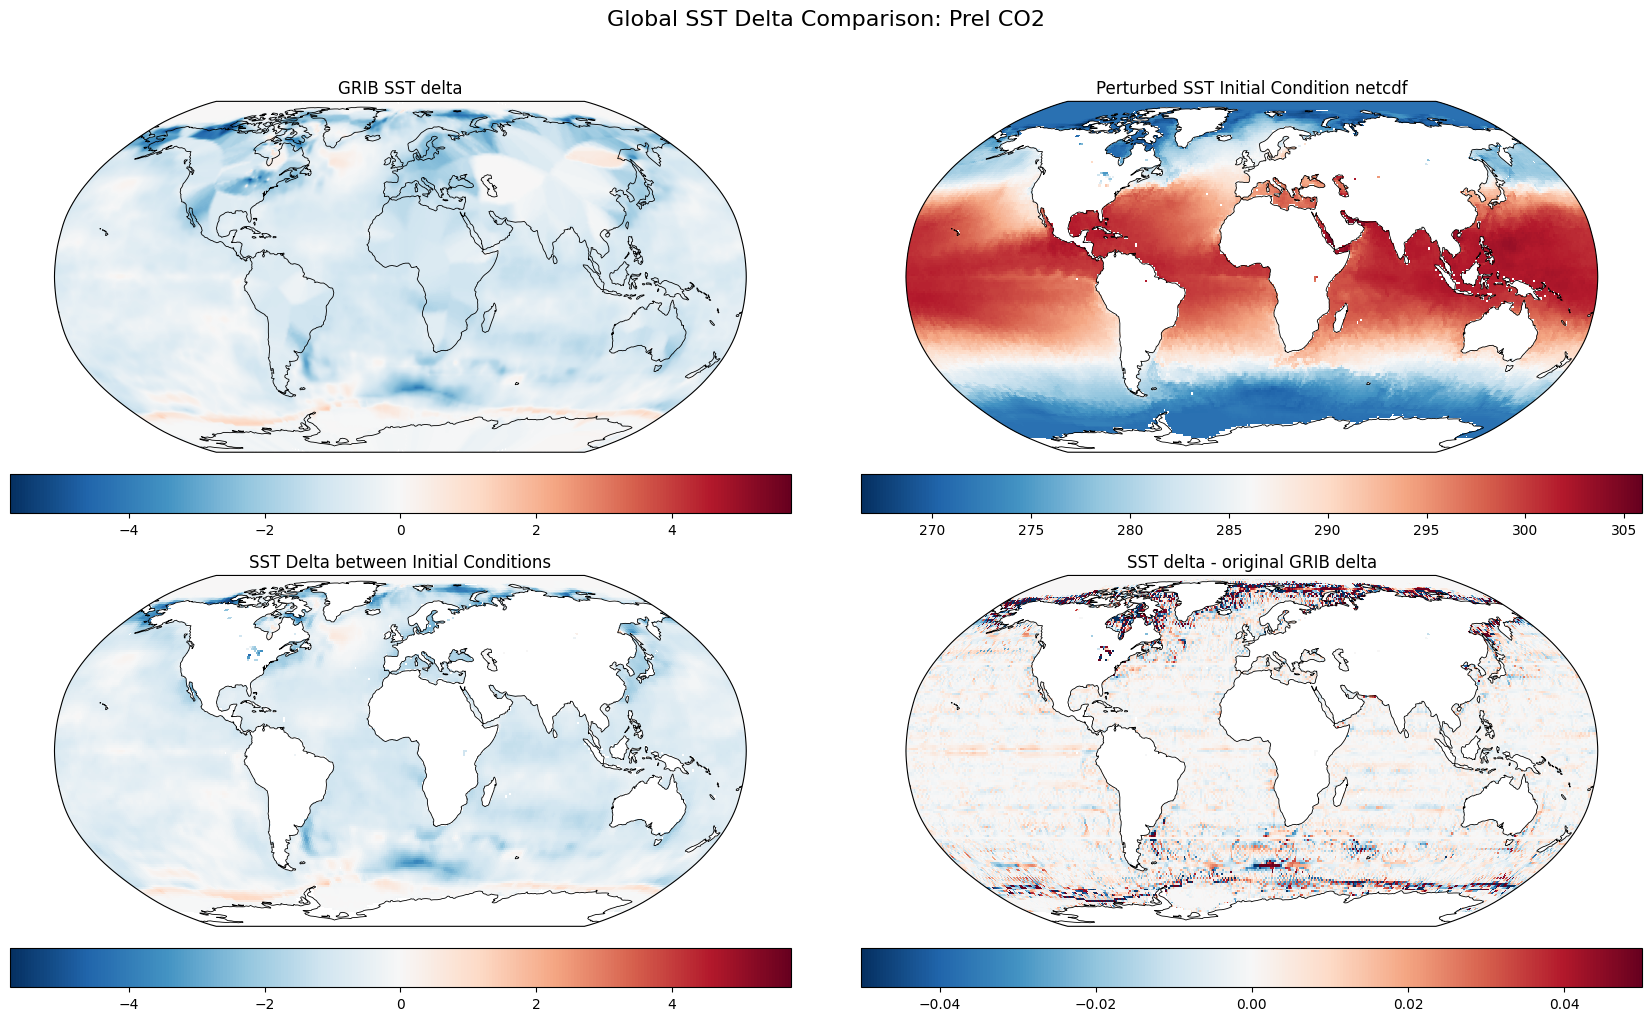

In [14]:
def canonicalize_1d_latlon(da):
    lat_name = next((n for n in ["latitude", "lat", "LATITUDE", "nav_lat"] if n in da.coords), None)
    lon_name = next((n for n in ["longitude", "lon", "LONGITUDE", "nav_lon"] if n in da.coords), None)

    if lat_name is None or lon_name is None:
        raise ValueError(f"Could not find lat/lon coords. dims={da.dims}, coords={list(da.coords)}")

    if lat_name not in da.dims and da[lat_name].ndim == 1:
        da = da.swap_dims({da[lat_name].dims[0]: lat_name})
    if lon_name not in da.dims and da[lon_name].ndim == 1:
        da = da.swap_dims({da[lon_name].dims[0]: lon_name})

    rename_map = {}
    if lat_name != "latitude":
        rename_map[lat_name] = "latitude"
    if lon_name != "longitude":
        rename_map[lon_name] = "longitude"
    if rename_map:
        da = da.rename(rename_map)

    lon = da["longitude"].values
    if np.nanmax(lon) > 180:
        da = da.assign_coords(longitude=((da["longitude"] + 180) % 360) - 180)

    return da.sortby("latitude").sortby("longitude").squeeze(drop=True)


def open_nc_sst(path):
    ds = xr.open_dataset(path)
    da = ds["sea_surface_temperature"].squeeze(drop=True)

    while da.ndim > 2:
        da = da.isel({da.dims[0]: 0}).squeeze(drop=True)

    return canonicalize_1d_latlon(da)


def open_grib_points(path):
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    da = ds["unknown"].squeeze(drop=True)

    if "values" not in da.dims:
        da = canonicalize_1d_latlon(da)
        return da

    lat = np.asarray(da["latitude"].values)
    lon = np.asarray(da["longitude"].values)
    vals = np.asarray(da.values)

    mask = np.isfinite(lat) & np.isfinite(lon) & np.isfinite(vals)
    lat = lat[mask]
    lon = lon[mask]
    vals = vals[mask]

    if np.nanmax(lon) > 180:
        lon = ((lon + 180) % 360) - 180

    return lat, lon, vals


def sample_points_to_grid(lat_pts, lon_pts, vals_pts, lat_grid, lon_grid):
    """
    Nearest-neighbour sample from scattered GRIB points onto a regular grid.
    This avoids xarray interp() on a point cloud.
    """
    tree = cKDTree(np.column_stack([lon_pts, lat_pts]))
    query_lon, query_lat = np.meshgrid(lon_grid, lat_grid)
    query_points = np.column_stack([query_lon.ravel(), query_lat.ravel()])
    _, idx = tree.query(query_points, k=1)
    sampled = vals_pts[idx].reshape(query_lat.shape)

    return xr.DataArray(
        sampled,
        coords={"latitude": lat_grid, "longitude": lon_grid},
        dims=("latitude", "longitude"),
        name="grib_sampled",
    )


def plot_grid(ax, da, title, cmap="RdBu_r", vmin=None, vmax=None):
    da = da.squeeze(drop=True).transpose("latitude", "longitude")
    lat = da["latitude"].values
    lon = da["longitude"].values
    data = da.values

    data_cyc, lon_cyc = add_cyclic_point(data, coord=lon)

    mesh = ax.pcolormesh(
        lon_cyc,
        lat,
        data_cyc,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.6)
    ax.set_global()
    plt.colorbar(mesh, ax=ax, orientation="horizontal", pad=0.05, shrink=0.85)
    return mesh


def plot_grib_points(ax, lat_pts, lon_pts, vals_pts, title, cmap="RdBu_r", vmin=None, vmax=None):
    sc = ax.scatter(
        lon_pts,
        lat_pts,
        c=vals_pts,
        s=1,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree(),
        linewidths=0,
        rasterized=True,
    )
    ax.set_title(title)
    ax.coastlines(linewidth=0.6)
    ax.set_global()
    plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.05, shrink=0.85)
    return sc


# Load NetCDF fields
init_da = open_nc_sst(init_nc_path)
out_da = open_nc_sst(out_nc_path)

# Load GRIB as raw scattered points
grib_lat, grib_lon, grib_vals = open_grib_points(grib_path)

# Make sure init/out are on the same grid
init_da, out_da = xr.align(init_da, out_da, join="inner")
delta_nc = out_da - init_da

# Sample GRIB points onto the NetCDF grid for comparison
grib_on_grid = sample_points_to_grid(
    grib_lat,
    grib_lon,
    grib_vals,
    init_da["latitude"].values,
    init_da["longitude"].values,
)

# Residual check
residual = delta_nc - grib_on_grid

print("Residual check:")
print(f"  max abs residual = {float(np.nanmax(np.abs(residual.values))):.6e}")
print(f"  mean residual    = {float(np.nanmean(residual.values)):.6e}")

# Shared scale for delta-style panels
delta_max = float(np.nanmax(np.abs(np.concatenate([
    grib_vals.ravel(),
    delta_nc.values.ravel(),
    residual.values.ravel(),
]))))

# Plot
fig = plt.figure(figsize=(18, 10))

ax1 = plt.subplot(2, 2, 1, projection=ccrs.Robinson())
plot_grib_points(ax1, grib_lat, grib_lon, grib_vals, "GRIB SST delta", cmap="RdBu_r", vmin=-delta_max, vmax=delta_max)

ax2 = plt.subplot(2, 2, 2, projection=ccrs.Robinson())
plot_grid(ax2, out_da, "Perturbed SST Initial Condition netcdf", cmap="RdBu_r")

ax3 = plt.subplot(2, 2, 3, projection=ccrs.Robinson())
plot_grid(ax3, delta_nc, "SST Delta between Initial Conditions", cmap="RdBu_r", vmin=-delta_max, vmax=delta_max)

ax4 = plt.subplot(2, 2, 4, projection=ccrs.Robinson())
plot_grid(ax4, residual, "SST delta - original GRIB delta", cmap="RdBu_r", vmin=-0.05, vmax=0.05)

fig.suptitle("Global SST Delta Comparison: PreI CO2", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

In [15]:
perturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr store
unperturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

In [16]:
perturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr store
unperturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

unperturbed = xr.open_zarr(unperturbed_zarr_path)[var]
perturbed   = xr.open_zarr(perturbed_zarr_path)[var]

# ---------------------------------------------------------
# 2. Standardize coordinate names
# ---------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

unperturbed = standardize(unperturbed)
perturbed   = standardize(perturbed)

init_time = np.datetime64("2021-06-18T00:00:00")
unperturbed = unperturbed.assign_coords(time=init_time + unperturbed.time)
perturbed   = perturbed.assign_coords(time=init_time + perturbed.time)

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

unperturbed = collapse_extra_dims(unperturbed)
perturbed   = collapse_extra_dims(perturbed)

unperturbed, perturbed = xr.align(unperturbed, perturbed, join="inner")

# ---------------------------------------------------------
# 4. Convert to Celsius and compute difference
# ---------------------------------------------------------
unperturbed = unperturbed - 273.15
perturbed   = perturbed - 273.15
diff        = perturbed - unperturbed

# ---------------------------------------------------------
# 5. Tidy dims
# ---------------------------------------------------------
def tidy(da):
    base = [d for d in ["time", "lat", "lon"] if d in da.dims]
    rest = [d for d in da.dims if d not in base]
    return da.transpose(*base, *rest) if base else da

unperturbed = tidy(unperturbed)
perturbed   = tidy(perturbed)
diff        = tidy(diff)

times = unperturbed.time.values
time_labels = [
    np.datetime_as_string(t, unit="h") if np.issubdtype(times.dtype, np.datetime64) else str(t)
    for t in times
]
slider_options = [(label, i) for i, label in enumerate(time_labels)]

# ---------------------------------------------------------
# 6. Plot helpers
# ---------------------------------------------------------
extent = [
    float(min(unperturbed.lon.min(), perturbed.lon.min())),
    float(max(unperturbed.lon.max(), perturbed.lon.max())),
    float(min(unperturbed.lat.min(), perturbed.lat.min())),
    float(max(unperturbed.lat.max(), perturbed.lat.max())),
]

sst_vals = np.concatenate([unperturbed.values.ravel(), perturbed.values.ravel()])
sst_vmin = np.nanpercentile(sst_vals, 2)
sst_vmax = np.nanpercentile(sst_vals, 98)

diff_abs = np.nanpercentile(np.abs(diff.values), 98)
diff_vmin = -diff_abs
diff_vmax = diff_abs

def draw_panel(ax, da2d, title, cmap, vmin, vmax, cbar_label):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.25)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    im = ax.pcolormesh(
        da2d.lon,
        da2d.lat,
        da2d,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title)
    cbar = ax.figure.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label(cbar_label)

slider = widgets.SelectionSlider(
    options=slider_options,
    value=0,
    description="Time",
    continuous_update=False,
    layout={"width": "800px"},
)

out = widgets.Output()

def show_frame(frame, pert):
    with out:
        clear_output(wait=True)

        # Force the selected timestep to load now, so the callback does not stall
        #unp_t = unperturbed.isel(time=frame).load()
        p_t = perturbed.isel(time=frame).load()
        dif_t = diff.isel(time=frame).load()

        fig, axes = plt.subplots(
            1, 2,
            figsize=(14, 6),
            subplot_kw={"projection": ccrs.PlateCarree()},
            constrained_layout=True
        )

        draw_panel(
            axes[0],
            p_t,
            "Perturbed SST",
            cmap="RdBu_r",
            vmin=sst_vmin,
            vmax=sst_vmax,
            cbar_label="SST (°C)"
        )

        draw_panel(
            axes[1],
            dif_t,
            "Perturbed - Unperturbed SST",
            cmap="RdBu_r",
            vmin=diff_vmin,
            vmax=diff_vmax,
            cbar_label="Difference (°C)"
        )

        fig.suptitle(f"{var} {pert} comparison — {time_labels[frame]}", fontsize=13)
        plt.show()
        plt.close(fig)

slider.observe(lambda change: show_frame(change["new"], "Incr CO2") if change["name"] == "value" else None, names="value")

display(widgets.VBox([slider, out]))
show_frame(0, "Incr CO2")

In [17]:
perturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr store
unperturbed_zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_26ens_0seed_predictions.zarr"   # folder or zarr storevar_name = "sea_surface_temperature"             # change if needed
var = "sea_surface_temperature"

unperturbed = xr.open_zarr(unperturbed_zarr_path)[var]
perturbed   = xr.open_zarr(perturbed_zarr_path)[var]

# ---------------------------------------------------------
# 2. Standardize coordinate names
# ---------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

unperturbed = standardize(unperturbed)
perturbed   = standardize(perturbed)

init_time = np.datetime64("2021-06-18T00:00:00")
unperturbed = unperturbed.assign_coords(time=init_time + unperturbed.time)
perturbed   = perturbed.assign_coords(time=init_time + perturbed.time)

unperturbed = collapse_extra_dims(unperturbed)
perturbed   = collapse_extra_dims(perturbed)

unperturbed, perturbed = xr.align(unperturbed, perturbed, join="inner")

# ---------------------------------------------------------
# 4. Convert to Celsius and compute difference
# ---------------------------------------------------------
unperturbed = unperturbed - 273.15
perturbed   = perturbed - 273.15
diff        = perturbed - unperturbed


unperturbed = tidy(unperturbed)
perturbed   = tidy(perturbed)
diff        = tidy(diff)

times = unperturbed.time.values
time_labels = [
    np.datetime_as_string(t, unit="h") if np.issubdtype(times.dtype, np.datetime64) else str(t)
    for t in times
]
slider_options = [(label, i) for i, label in enumerate(time_labels)]

# ---------------------------------------------------------
# 6. Plot helpers
# ---------------------------------------------------------
extent = [
    float(min(unperturbed.lon.min(), perturbed.lon.min())),
    float(max(unperturbed.lon.max(), perturbed.lon.max())),
    float(min(unperturbed.lat.min(), perturbed.lat.min())),
    float(max(unperturbed.lat.max(), perturbed.lat.max())),
]

sst_vals = np.concatenate([unperturbed.values.ravel(), perturbed.values.ravel()])
sst_vmin = np.nanpercentile(sst_vals, 2)
sst_vmax = np.nanpercentile(sst_vals, 98)

diff_abs = np.nanpercentile(np.abs(diff.values), 98)
diff_vmin = -diff_abs
diff_vmax = diff_abs


slider = widgets.SelectionSlider(
    options=slider_options,
    value=0,
    description="Time",
    continuous_update=False,
    layout={"width": "800px"},
)

out = widgets.Output()

slider.observe(lambda change: show_frame(change["new"], "Pre Ind CO2") if change["name"] == "value" else None, names="value")

display(widgets.VBox([slider, out]))
show_frame(0, "Pre Ind CO2")

In [ ]:
perturbed_netcdf = "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc"
unperturbed_netcdf = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-18.nc"

var = "t2m"

perturbed = xr.open_dataset(perturbed_netcdf)[var]
unperturbed = xr.open_dataset(unperturbed_netcdf)[var]

# ---------------------------------------------------------
# 2. Standardize coordinate names
# ---------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

perturbed = standardize(perturbed)
unperturbed = standardize(unperturbed)

# ---------------------------------------------------------
# 3. Convert time coords if they are lead times
#    (use the date in the filepath as the forecast start)
# ---------------------------------------------------------
def extract_date_from_path(path):
    m = re.search(r"(20\d{2}-\d{2}-\d{2})", path)
    if not m:
        return None
    return np.datetime64(m.group(1) + "T00:00:00")

def to_valid_time(da, init_time):
    if "time" not in da.coords or init_time is None:
        return da

    t = da["time"]

    if np.issubdtype(t.dtype, np.datetime64):
        return da

    if np.issubdtype(t.dtype, np.timedelta64):
        return da.assign_coords(time=init_time + t)

    if np.issubdtype(t.dtype, np.number):
        return da.assign_coords(time=init_time + t * np.timedelta64(1, "h"))

    return da

pert_init_time = extract_date_from_path(perturbed_netcdf)
unpert_init_time = extract_date_from_path(unperturbed_netcdf)

perturbed = to_valid_time(perturbed, pert_init_time)
unperturbed = to_valid_time(unperturbed, unpert_init_time)

# ---------------------------------------------------------
# 4. Collapse extra dims and align
# ---------------------------------------------------------
def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

perturbed = collapse_extra_dims(perturbed)
unperturbed = collapse_extra_dims(unperturbed)

perturbed, unperturbed = xr.align(perturbed, unperturbed, join="inner")

# ---------------------------------------------------------
# 5. Convert SST to Celsius and compute difference
# ---------------------------------------------------------
perturbed = perturbed - 273.15
unperturbed = unperturbed - 273.15
diff = unperturbed - perturbed

# ---------------------------------------------------------
# 6. Tidy dims
# ---------------------------------------------------------
def tidy(da):
    base = [d for d in ["time", "lat", "lon"] if d in da.dims]
    rest = [d for d in da.dims if d not in base]
    return da.transpose(*base, *rest) if base else da

perturbed = tidy(perturbed)
unperturbed = tidy(unperturbed)
diff = tidy(diff)

# ---------------------------------------------------------
# 7. Plot settings: use all available area
# ---------------------------------------------------------
extent = [
    float(min(unperturbed.lon.min(), perturbed.lon.min())),
    float(max(unperturbed.lon.max(), perturbed.lon.max())),
    float(min(unperturbed.lat.min(), perturbed.lat.min())),
    float(max(unperturbed.lat.max(), perturbed.lat.max())),
]

times = unperturbed.time.values
time_labels = [
    np.datetime_as_string(t, unit="h") if np.issubdtype(times.dtype, np.datetime64) else str(t)
    for t in times
]
slider_options = [(label, i) for i, label in enumerate(time_labels)]

sst_vals = np.concatenate([unperturbed.values.ravel(), perturbed.values.ravel()])
sst_vmin = np.nanpercentile(sst_vals, 2)
sst_vmax = np.nanpercentile(sst_vals, 98)

diff_abs = np.nanpercentile(np.abs(diff.values), 98)
diff_vmin = -diff_abs
diff_vmax = diff_abs

def draw_panel(ax, da2d, title, cmap, vmin, vmax, cbar_label):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.25)

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 9}
    gl.ylabel_style = {"size": 9}

    im = ax.pcolormesh(
        da2d.lon,
        da2d.lat,
        da2d,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title)
    cbar = ax.figure.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label(cbar_label)

def show_frame(frame):
    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 6),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True
    )

    draw_panel(
        axes[0],
        unperturbed.isel(time=frame),
        "Unperturbed SST",
        cmap="RdBu_r",
        vmin=sst_vmin,
        vmax=sst_vmax,
        cbar_label="SST (°C)"
    )

    draw_panel(
        axes[1],
        diff.isel(time=frame),
        "Unperturbed - Perturbed SST",
        cmap="RdBu_r",
        vmin=diff_vmin,
        vmax=diff_vmax,
        cbar_label="Difference (°C)"
    )

    fig.suptitle(f"{var} comparison — {time_labels[frame]}", fontsize=13)
    plt.show()
    plt.close(fig)

slider = widgets.SelectionSlider(
    options=slider_options,
    value=0,
    description="Time",
    continuous_update=False,
    layout={"width": "800px"},
)

out = widgets.Output()

def on_change(change):
    if change["name"] == "value":
        with out:
            clear_output(wait=True)
            show_frame(change["new"])

slider.observe(on_change, names="value")

display(widgets.VBox([slider, out]))
with out:
    show_frame(0)

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# Inputs
# -------------------------------------------------------------------
unperturbed_paths = ["/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-18.nc"]

scenario_paths = {
    "incr": [
        "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mq_2021-06-18.nc",
    ],
    "pi": [
        "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
    ],
}

var = "sst"   # change if your SST variable has a different name

# -------------------------------------------------------------------
# Helpers
# -------------------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

def load_many(paths, var):
    das = []
    for p in paths:
        da = xr.open_dataset(p)[var]
        da = standardize(da)
        da = collapse_extra_dims(da)
        das.append(da)

    if len(das) == 1:
        return das[0]

    return xr.concat(das, dim="time").sortby("time")

def area_weighted_mean(da):
    if "lat" not in da.dims or "lon" not in da.dims:
        return da.mean()

    weights = np.cos(np.deg2rad(da["lat"]))
    return da.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

def to_step_axis(da):
    if "time" in da.dims:
        da = da.rename({"time": "step"})
    da = da.assign_coords(step=np.arange(da.sizes["step"]))
    return da

# -------------------------------------------------------------------
# Load and convert to Celsius
# -------------------------------------------------------------------
unperturbed = load_many(unperturbed_paths, var) - 273.15
scenario_data = {name: load_many(paths, var) - 273.15 for name, paths in scenario_paths.items()}

# -------------------------------------------------------------------
# Area-mean SST time series
# -------------------------------------------------------------------
unpert_mean = to_step_axis(area_weighted_mean(unperturbed))

scenario_means = {}
scenario_deltas = {}

for name, da in scenario_data.items():
    mean = to_step_axis(area_weighted_mean(da))

    # compare on common forecast-output index
    mean_aligned, unpert_aligned = xr.align(mean, unpert_mean, join="inner")

    scenario_means[name] = mean_aligned
    scenario_deltas[name] = mean_aligned - unpert_aligned

# -------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)

# Top: mean SST
axes[0].plot(unpert_mean["step"], unpert_mean, label="Unperturbed", linewidth=2)
for name, series in scenario_means.items():
    axes[0].plot(series["step"], series, linewidth=2, label=f"{name.upper()} perturbation")

axes[0].set_ylabel("Mean SST (°C)")
axes[0].set_title("Area-mean SST")
axes[0].legend()

# Bottom: delta relative to unperturbed
for name, delta in scenario_deltas.items():
    axes[1].plot(delta["step"], delta, linewidth=2, label=f"{name.upper()} − Unperturbed")

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_ylabel("Δ SST (°C)")
axes[1].set_title("Area-mean SST anomaly relative to unperturbed")
axes[1].legend()

axes[1].set_xlabel("Forecast output index")
plt.show()

KeyError: "No variable named 'sst'. Variables on the dataset include ['swvl1', 'tcwv', 'tcc', 't2m', 'e', ..., 'tp', 'longitude', 'latitude', 'number', 'time']"

In [3]:
zarr_path = "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-18T00_26d_26ens_0seed_predictions.zarr"

# Try common temperature variable names
ds = xr.open_zarr(zarr_path)
print("Available variables:")
print(list(ds.data_vars))

Available variables:
['10m_u_component_of_wind', '10m_v_component_of_wind', '2m_temperature', 'day_progress_cos', 'day_progress_sin', 'geopotential', 'geopotential_at_surface', 'land_sea_mask', 'mean_sea_level_pressure', 'sea_surface_temperature', 'specific_humidity', 'temperature', 'total_precipitation_12hr', 'u_component_of_wind', 'v_component_of_wind', 'vertical_velocity', 'year_progress_cos', 'year_progress_sin']


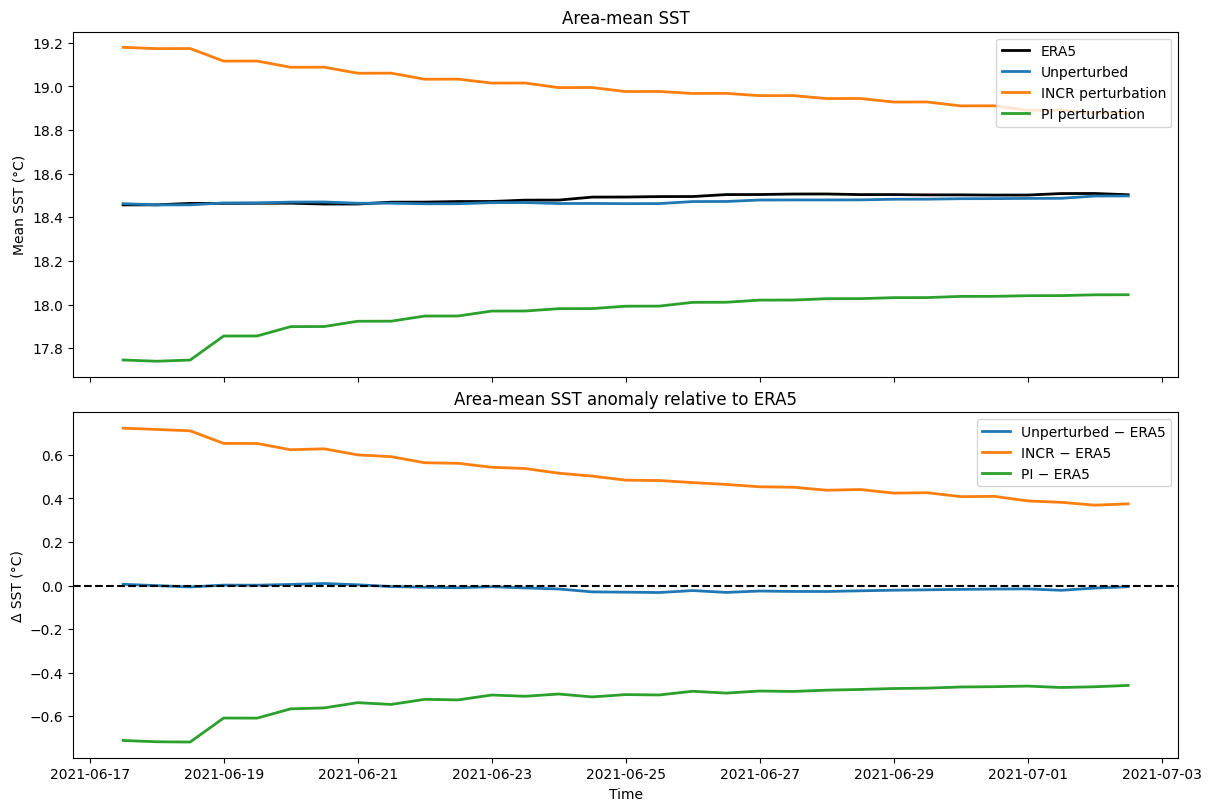

In [13]:
unperturbed_paths = [
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr"
]
era5_path = "init_files/init_2021-06-17T12_30d.nc"
var = "sea_surface_temperature"

scenario_paths = {
    "incr": [
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
    ],
    "pi": [
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
    ],
}

# -------------------------------------------------------------------
# Helpers
# -------------------------------------------------------------------
def open_any(path):
    if path.endswith(".zarr"):
        return xr.open_zarr(path)
    return xr.open_dataset(path)

def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

def extract_date_from_path(path):
    m = re.search(r"(20\d{2}-\d{2}-\d{2})", path)
    return np.datetime64(m.group(1) + "T00:00:00") if m else None

def squeeze_series(da):
    return da.squeeze(drop=True)

def to_valid_time(da, init_time):
    if "time" not in da.coords or init_time is None:
        return da

    t = da["time"]

    if np.issubdtype(t.dtype, np.datetime64):
        return da

    if np.issubdtype(t.dtype, np.timedelta64):
        return da.assign_coords(time=init_time + t)

    if np.issubdtype(t.dtype, np.number):
        return da.assign_coords(time=init_time + t * np.timedelta64(1, "h"))

    return da

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

def load_many(paths, var):
    das = []
    for p in paths:
        ds = open_any(p)
        da = ds[var]
        da = standardize(da)
        da = to_valid_time(da, extract_date_from_path(p))
        da = collapse_extra_dims(da)
        das.append(da)

    if len(das) == 1:
        return das[0]

    return xr.concat(das, dim="time").sortby("time")

def area_weighted_mean(da):
    if "lat" not in da.dims or "lon" not in da.dims:
        return da.mean()

    weights = np.cos(np.deg2rad(da["lat"]))
    return da.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

# -------------------------------------------------------------------
# Load data
# -------------------------------------------------------------------
unperturbed = load_many(unperturbed_paths, var)

era5_ds = open_any(era5_path)
era5 = standardize(era5_ds[var])
era5 = to_valid_time(era5, extract_date_from_path(era5_path))

# Convert K -> C
unperturbed = unperturbed - 273.15
era5 = era5 - 273.15

# Align unperturbed with ERA5
unperturbed, era5 = xr.align(unperturbed, era5, join="inner")

# Area-mean time series
unpert_mean = squeeze_series(area_weighted_mean(unperturbed))
era5_mean = squeeze_series(area_weighted_mean(era5))

# Keep only the common time axis for plotting
unpert_mean, era5_mean = xr.align(unpert_mean, era5_mean, join="inner")
unpert_delta = squeeze_series(unpert_mean - era5_mean)

# -------------------------------------------------------------------
# Load perturbed scenarios
# -------------------------------------------------------------------
scenario_means = {}
scenario_deltas = {}

for name, paths in scenario_paths.items():
    da = load_many(paths, var)
    da = da - 273.15  # K -> C

    da, era5_aligned = xr.align(da, era5, join="inner")

    mean = squeeze_series(area_weighted_mean(da))
    era5_mean_aligned = squeeze_series(area_weighted_mean(era5_aligned))

    mean, era5_mean_aligned = xr.align(mean, era5_mean_aligned, join="inner")

    scenario_means[name] = mean
    scenario_deltas[name] = squeeze_series(mean - era5_mean_aligned)

# -------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

# Top panel: mean SST
axes[0].plot(
    era5_mean.time,
    era5_mean,
    label="ERA5",
    linewidth=2,
    color="black",
)

axes[0].plot(
    unpert_mean.time,
    unpert_mean,
    label="Unperturbed",
    linewidth=2,
)

for name, series in scenario_means.items():
    axes[0].plot(
        series.time,
        series,
        linewidth=2,
        label=f"{name.upper()} perturbation",
    )

axes[0].set_ylabel("Mean SST (°C)")
axes[0].set_title("Area-mean SST")
axes[0].legend()

# Bottom panel: delta vs ERA5
axes[1].plot(
    unpert_delta.time,
    unpert_delta,
    linewidth=2,
    label="Unperturbed − ERA5",
)

for name, delta in scenario_deltas.items():
    axes[1].plot(
        delta.time,
        delta,
        linewidth=2,
        label=f"{name.upper()} − ERA5",
    )

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Δ SST (°C)")
axes[1].set_title("Area-mean SST anomaly relative to ERA5")
axes[1].legend()

plt.xlabel("Time")
plt.show()

In [11]:
unperturbed_paths = ["/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-18.nc"]
era5_path = "init_files/init_2021-06-17T12_30d.nc"
var = "t2m"

scenario_paths = {
    "incr": [
        "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mq_2021-06-18.nc",
    ],
    "pi": [
        "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-22.nc",
    ],
}

# -------------------------------------------------------------------
# Helpers
# -------------------------------------------------------------------
def standardize(da):
    rename = {}
    if "latitude" in da.coords:
        rename["latitude"] = "lat"
    if "longitude" in da.coords:
        rename["longitude"] = "lon"
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    if "sample" in da.dims:
        rename["sample"] = "number"
    if "member" in da.dims:
        rename["member"] = "number"
    if rename:
        da = da.rename(rename)
    return da

def extract_date_from_path(path):
    m = re.search(r"(20\d{2}-\d{2}-\d{2})", path)
    return np.datetime64(m.group(1) + "T00:00:00") if m else None

def to_valid_time(da, init_time):
    if "time" not in da.coords or init_time is None:
        return da

    t = da["time"]

    if np.issubdtype(t.dtype, np.datetime64):
        return da

    if np.issubdtype(t.dtype, np.timedelta64):
        return da.assign_coords(time=init_time + t)

    if np.issubdtype(t.dtype, np.number):
        return da.assign_coords(time=init_time + t * np.timedelta64(1, "h"))

    return da

def collapse_extra_dims(da):
    for dim in ["batch", "number", "sample", "member", "ensemble"]:
        if dim in da.dims:
            da = da.mean(dim)
    return da

def load_many(paths, var):
    das = []
    for p in paths:
        da = xr.open_dataset(p)[var]
        da = standardize(da)
        da = to_valid_time(da, extract_date_from_path(p))
        da = collapse_extra_dims(da)
        das.append(da)

    if len(das) == 1:
        return das[0]

    return xr.concat(das, dim="time").sortby("time")

def area_weighted_mean(da):
    if "lat" not in da.dims or "lon" not in da.dims:
        return da.mean()

    weights = np.cos(np.deg2rad(da["lat"]))
    return da.weighted(weights).mean(dim=("lat", "lon"), skipna=True)

# -------------------------------------------------------------------
# Load data
# -------------------------------------------------------------------
unperturbed = load_many(unperturbed_paths, var)
era5 = standardize(xr.open_dataset(era5_path)[var])
era5 = to_valid_time(era5, extract_date_from_path(era5_path))

# Convert K -> C
unperturbed = unperturbed - 273.15
era5 = era5 - 273.15

# Align unperturbed with ERA5
unperturbed, era5 = xr.align(unperturbed, era5, join="inner")

# Area-mean time series
unpert_mean = area_weighted_mean(unperturbed)
era5_mean = area_weighted_mean(era5)

# Keep only the common time axis for plotting
unpert_mean, era5_mean = xr.align(unpert_mean, era5_mean, join="inner")
unpert_delta = unpert_mean - era5_mean

# -------------------------------------------------------------------
# Load perturbed scenarios
# -------------------------------------------------------------------
scenario_means = {}
scenario_deltas = {}

for name, paths in scenario_paths.items():
    da = load_many(paths, var)
    da = da - 273.15  # K -> C

    da, era5_aligned = xr.align(da, era5, join="inner")

    mean = area_weighted_mean(da)
    era5_mean_aligned = area_weighted_mean(era5_aligned)

    mean, era5_mean_aligned = xr.align(mean, era5_mean_aligned, join="inner")

    scenario_means[name] = mean
    scenario_deltas[name] = mean - era5_mean_aligned

# -------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

# Top panel: mean SST
axes[0].plot(
    era5_mean.time,
    era5_mean,
    label="ERA5",
    linewidth=2,
    color="black",
)

axes[0].plot(
    unpert_mean.time,
    unpert_mean,
    label="Unperturbed",
    linewidth=2,
)

for name, series in scenario_means.items():
    axes[0].plot(
        series.time,
        series,
        linewidth=2,
        label=f"{name.upper()} perturbation",
    )

axes[0].set_ylabel("Mean SST (°C)")
axes[0].set_title("Area-mean SST")
axes[0].legend()

# Bottom panel: delta vs ERA5
axes[1].plot(
    unpert_delta.time,
    unpert_delta,
    linewidth=2,
    label="Unperturbed − ERA5",
)

for name, delta in scenario_deltas.items():
    axes[1].plot(
        delta.time,
        delta,
        linewidth=2,
        label=f"{name.upper()} − ERA5",
    )

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Δ SST (°C)")
axes[1].set_title("Area-mean SST anomaly relative to ERA5")
axes[1].legend()

plt.xlabel("Time")
plt.show()

KeyError: "No variable named 't2m'. Variables on the dataset include ['geopotential', 'specific_humidity', 'temperature', 'u_component_of_wind', 'v_component_of_wind', ..., 'time', 'level', 'lat', 'lon', 'datetime']"